# 06 · Final benchmark on the held-out test period
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mvya0005/mma3001-project-sensor-reconstruction/blob/main/notebooks/06_final_benchmark_and_validation.ipynb)

This is the **only** notebook that touches the test period (22 May – 14 Jun 2024). All method choices, hyperparameters and the hybrid threshold come from notebooks 01–05 (validation period). Every method sees **identical** artificial gaps (`study.FINAL_PROTOCOL`: 7 gap lengths × up to 30 gaps × 5 independent mask draws).

Contents: (1) accuracy with confidence intervals, (2) the selected hybrid policy, (3) the engineering indicator (daily CO₂ dose) and quadrature error, (4) runtime, memory, FLOPs and the roofline, (5) temperature, (6) generalisation to a second sensor, (7) failure modes and limitations.

In [1]:
# ---- Environment setup: works on Google Colab and locally ----
import os, sys, subprocess
from pathlib import Path

GITHUB_REPO = "mvya0005/mma3001-project-sensor-reconstruction"  # owner/name of this repository
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    repo_dir = Path("/content") / GITHUB_REPO.split("/")[1]
    if not repo_dir.exists():
        subprocess.run(["git", "clone", "-q", f"https://github.com/{GITHUB_REPO}.git", str(repo_dir)], check=True)
    os.chdir(repo_dir)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "."], check=True)
    sys.path.insert(0, str(repo_dir / "src"))  # editable install is not visible until restart
    from google.colab import drive
    drive.mount("/content/drive")
    RAW = Path("/content/drive/MyDrive/MMA3001/raw")              # put the two Moodle zip files here
    PROCESSED = Path("/content/drive/MyDrive/MMA3001/processed")  # cached across Colab sessions
else:
    if Path.cwd().name == "notebooks":
        os.chdir("..")
    sys.path.insert(0, str(Path("src").resolve()))
    RAW, PROCESSED = Path("data/raw"), Path("data/processed")

PROCESSED.mkdir(parents=True, exist_ok=True)
if not (PROCESSED / "audit.json").exists():
    subprocess.run([sys.executable, "scripts/preprocess.py", "--raw", str(RAW), "--out", str(PROCESSED)], check=True)
print("repository:", Path.cwd(), "| processed data:", PROCESSED)

repository: /home/claude/mma3001-sensor-reconstruction | processed data: data/processed


In [2]:
import json
import numpy as np
import pandas as pd
from sensorfill import benchmark as bm, features as ft, interpolation as itp, ml, ode, pde, profiling, quadrature as q, study, plotting
from sensorfill.masking import block_mask, apply_mask
from sensorfill.plotting import plt
plotting.setup()
s = study.load_study(PROCESSED, "co2")
(y_tr, ts_tr, o_tr), (y_v, ts_v, o_v), (y_te, ts_te, o_te) = s.part("train"), s.part("val"), s.part("test")
best_params = json.loads(Path("reports/ml_best_params.json").read_text())
h = study.DT_HOURS

# Models are fitted on the training period only, exactly as validated.
def builder(st, ts, occ, use_occ=True):
    return ft.GapFeatureBuilder(ts, occ if use_occ else None, st.profile_values(ts), level_ref=st.level_ref)
X, r, g = ft.make_training_set(y_tr, builder(s, ts_tr, o_tr), gap_lengths=study.GAP_LENGTHS, rng=0)
ridge = ml.MLImputer(ml.make_model("ridge", **best_params["ridge"]), builder(s, ts_te, o_te)).fit(X, r)
forest = ml.MLImputer(ml.make_model("forest", **best_params["forest"]), builder(s, ts_te, o_te)).fit(X, r)
yf, of = itp.fill_linear(y_tr), itp.fill_locf(o_tr)
segs = [(np.arange(144) * h, yf[i:i + 144], of[i:i + 144]) for i in range(0, len(yf) - 144, 144)]
p_ode, _ = ode.fit_output_error(segs, ode.fit_equation_error(yf, of, h))
print("ODE parameters:", p_ode)

ODE parameters: CO2Params(g=np.float64(4.47241118581852), lam=np.float64(0.6291111609196152), c_out=np.float64(449.9946371499734), s=0.0)


## 1. The hybrid policy, chosen on validation data
Notebook 04 showed that linear interpolation is best for short gaps and the learned correction is best for long ones. The switch-over length is chosen as the longest validation gap length for which linear interpolation still had the lower RMSE.

In [3]:
val = pd.read_csv("reports/val_ml.csv")
v = val[val.method.isin(["Linear", "ridge +occ"])].groupby(["gap_len", "method"]).rmse.mean().unstack()
linear_wins = v["Linear"] <= v["ridge +occ"]
threshold = int(v.index[linear_wins].max()) if linear_wins.any() else 0
print(v.round(2)); print("-> use linear for gaps of at most", threshold, "steps; ridge correction above")

method   Linear  ridge +occ
gap_len                    
1         10.40       12.18
3         11.43       13.27
6         12.13       14.23
18        14.77       15.06
36        22.41       20.13
72        30.91       21.10
144       48.61       30.67
-> use linear for gaps of at most 18 steps; ridge correction above


## 2. Accuracy on the test period

In [4]:
methods = {
    "Linear": lambda y, c: itp.fill_linear(y),
    "PCHIP": lambda y, c: itp.fill_pchip(y),
    "Daily profile + offset": lambda y, c: itp.fill_profile(y, c.ts, profile=s.train_profile),
    "ODE shooting (grey box)": lambda y, c: ode.fill_ode(y, c.occ, p_ode, h, mode="shooting"),
    "Ridge correction (+occ)": lambda y, c: ridge.impute(y),
    "Random forest correction (+occ)": lambda y, c: forest.impute(y),
}
methods["Hybrid (validated policy)"] = bm.hybrid_method(methods["Linear"], methods["Ridge correction (+occ)"], threshold)
ctx = bm.Context(ts=ts_te, occ=o_te, profile=s.train_profile)
test = bm.run_benchmark(y_te, ctx, methods, **study.FINAL_PROTOCOL)
deep_file = Path("reports/test_deep.csv")
if deep_file.exists():
    deep = pd.read_csv(deep_file)
    print("including GPU deep-learning results from notebook 05 (device:", deep["device"].iloc[0], ")")
    test = pd.concat([test, deep.drop(columns="device")], ignore_index=True)
else:
    print("reports/test_deep.csv not found - run notebook 05 on Colab to add the deep models")
test.to_csv("reports/test_results.csv", index=False)
ci = bm.confidence_table(test)
tab = (ci["mean"].round(1).astype(str) + " ± " + ci["ci95"].round(1).astype(str)).unstack()
tab = tab.loc[bm.summarise(test).index]
tab

including GPU deep-learning results from notebook 05 (device: cuda )


gap_len,1,3,6,18,36,72,144
method,,,,,,,
PI-BiGRU (w=0.003),8.7 ± 1.5,10.0 ± 1.3,11.3 ± 2.0,12.2 ± 1.8,16.0 ± 1.2,18.1 ± 1.4,21.4 ± 1.8
BiGRU,8.6 ± 1.6,10.0 ± 1.2,11.3 ± 1.9,12.2 ± 1.8,16.0 ± 1.3,18.2 ± 1.3,21.4 ± 1.8
Linear,8.3 ± 2.0,9.9 ± 0.9,11.0 ± 1.4,12.0 ± 1.3,15.0 ± 1.5,18.9 ± 1.8,24.3 ± 1.4
PCHIP,8.6 ± 2.0,10.2 ± 1.0,11.8 ± 1.6,12.8 ± 1.5,15.8 ± 1.4,20.2 ± 3.1,25.2 ± 1.9
ODE shooting (grey box),8.3 ± 2.0,9.9 ± 0.9,10.9 ± 1.3,12.7 ± 1.7,17.2 ± 1.4,22.5 ± 2.6,25.8 ± 4.4
Random forest correction (+occ),8.2 ± 1.6,9.4 ± 0.6,10.1 ± 0.9,11.9 ± 1.6,15.4 ± 1.6,18.8 ± 2.1,25.8 ± 3.5
Ridge correction (+occ),9.1 ± 1.1,10.5 ± 1.2,11.8 ± 1.7,12.4 ± 1.4,16.7 ± 2.0,19.4 ± 1.0,25.9 ± 2.1
Hybrid (validated policy),8.3 ± 2.0,9.9 ± 0.9,11.0 ± 1.4,12.0 ± 1.3,16.7 ± 2.0,19.4 ± 1.0,25.9 ± 2.1
Neural ODE,9.2 ± 1.3,11.3 ± 1.3,13.6 ± 2.3,19.9 ± 3.6,24.7 ± 1.8,26.6 ± 1.1,28.8 ± 2.6


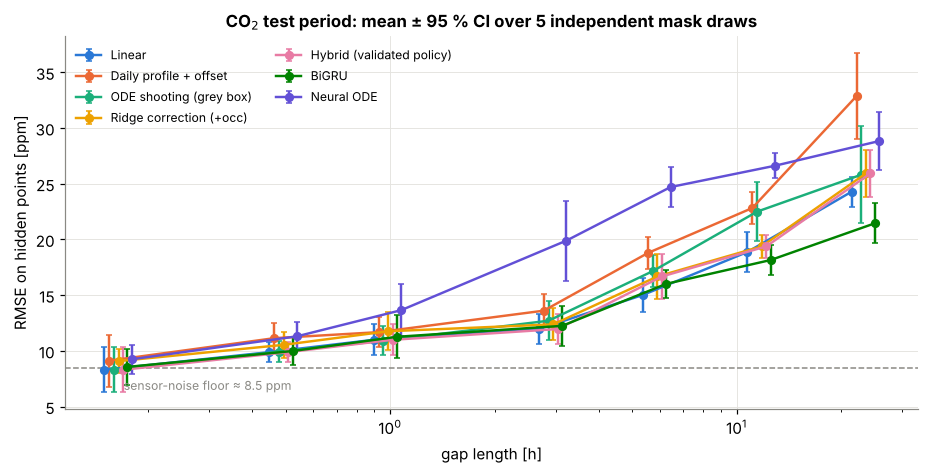

In [5]:
order = list(bm.summarise(test).index)
fig, ax = plt.subplots(figsize=(10, 4.4))
show = [m for m in ["Linear", "Daily profile + offset", "ODE shooting (grey box)", "Ridge correction (+occ)", "Hybrid (validated policy)", "BiGRU", "Neural ODE"] if m in order]
for i, name in enumerate(show):
    d = ci.loc[name]
    x = d.index.to_numpy() * 10 / 60
    ax.errorbar(x * (1 + 0.03 * (i - len(show) / 2)), d["mean"], yerr=d["ci95"], marker="o", capsize=2, color=plotting.PALETTE[i], label=name)
ax.axhline(8.5, color=plotting.MUTED, ls="--", lw=1); ax.text(0.17, 6.5, "sensor-noise floor ≈ 8.5 ppm", color=plotting.MUTED, fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("gap length [h]"); ax.set_ylabel("RMSE on hidden points [ppm]")
ax.legend(fontsize=8, ncol=2); ax.set_title("CO$_2$ test period: mean ± 95 % CI over 5 independent mask draws")
_ = plotting.save(fig, "06_test_rmse")

In [6]:
pd.DataFrame({m: {"bias": test[test.method == m].bias.mean(), "MAE": test[test.method == m].mae.mean(),
                  "worst point error": test[test.method == m].max_err.max(), "R² (24 h gaps)": test[(test.method == m) & (test.gap_len == 144)].r2.mean()}
              for m in order}).T.round(2)

,bias,MAE,worst point error,R² (24 h gaps)
PI-BiGRU (w=0.003),-1.31,10.35,145.59,0.45
BiGRU,-1.36,10.35,146.21,0.45
Linear,-0.14,10.64,145.97,0.28
PCHIP,-0.20,11.24,146.97,0.23
ODE shooting (grey box),0.13,11.46,183.06,0.20
Random forest correction (+occ),0.77,10.69,156.55,0.19
Ridge correction (+occ),0.85,11.56,153.32,0.18
Hybrid (validated policy),0.80,11.29,153.32,0.18
Neural ODE,0.69,15.08,126.45,-0.00
Daily profile + offset,-0.32,13.31,167.02,-0.31


**Statistical note.** The 95 % intervals come from the 5 independent mask draws. Where two methods' intervals overlap, as for most short-gap comparisons, the data do not distinguish them, and the simpler method should be preferred.

**The validated policy did not survive the test period.** This is the most important result of the project, so it is stated plainly:
* On validation, the ridge correction cut the 24-h error of linear interpolation from about 49 to 31 ppm, so the hybrid policy switched to it above 3 h. On test, the hybrid is worse than linear, or no better within the confidence interval, for every gap length above 3 h (e.g. about 26 vs 24 ppm at 24 h).
* The cause is a **distribution shift**, not a coding error. Linear interpolation's own 24-h error halves from validation to test (≈ 49 → 24 ppm), so the test period (22 May – 14 Jun, end of semester) is much calmer. The learned correction and the training-period daily profile both still add a working-day rise that no longer happens. That shows up as a positive bias for ridge and the hybrid, and in the dose table below (they over-estimate the daily dose by about 8 % on average). The profile, which depends most on the training schedule, becomes the *worst* method at 24 h.
* The **BiGRU** (notebook 05, trained on a Colab T4 GPU) is the only method better than linear on *both* periods for 24-h gaps (validation about 30 vs 49 ppm; test 21.4 ± 1.8 vs 24.3 ± 1.4 ppm, about 12 % lower, with intervals that only just overlap). It also has the highest R² (0.45 vs 0.28). At 6 h it is slightly worse than linear, and at 12 h the two are within the confidence intervals. The physics-informed variant chosen on validation is indistinguishable from it. It uses a whole 3-day window around the gap rather than a fixed typical day, which is the likely reason it adapts to the calmer period.
* For gaps up to an hour, the forest correction has the lowest mean, but the intervals overlap with linear. The difference is not significant, and linear is about 2,000× cheaper.

Lesson: one validation period from the same semester was not enough to choose between methods whose advantage depends on the building's schedule. Validation over several regimes (e.g. rolling-origin validation) would have flagged it.

## 3. Engineering indicator: daily CO₂ dose, and quadrature error
The ventilation indicator is the daily excess dose $D = \int_{\text{day}} \max(C - 420, 0)\,dt$ [ppm·h]. One 6-hour gap is hidden inside working hours on each test day. The gap is reconstructed, *D* is recomputed, and the result is compared with *D* from the observed day.

**First, is the quadrature itself accurate enough?** For a smooth reconstruction, the trapezoid and Simpson rules on 10-min samples should agree to well within the reconstruction error. This is checked against Romberg and Gauss–Legendre integration of a cubic-spline representation of each day.

In [7]:
ts_days = pd.DatetimeIndex(ts_te)
rows = []
for day in sorted(set(ts_days.date))[:10]:
    sel = ts_days.date == day
    yd = itp.fill_linear(y_te[sel])
    if len(yd) != 144: continue
    e = q.excess(yd, 420.0)
    tt = np.arange(144) * h
    coef = itp.natural_spline_coefficients(tt, e)
    f = lambda t: itp.spline_evaluate(coef, t)
    rows.append({"day": day, "trapezoid": q.trapezoid(e, h), "Simpson": q.simpson_any(e, h),
                 "Romberg (spline)": q.romberg(f, 0, tt[-1], max_level=12, tol=1e-9)[0],
                 "Gauss-Legendre 5x36 (spline)": q.gauss_legendre(f, 0, tt[-1], n=5, panels=36)})
quad = pd.DataFrame(rows).set_index("day")
quad["max rule spread [%]"] = 100 * (quad.max(axis=1) - quad.min(axis=1)) / quad.mean(axis=1)
quad.round(2)

,trapezoid,Simpson,Romberg (spline),Gauss-Legendre 5x36 (spline),max rule spread [%]
day,,,,,
2024-05-22,2161.17,2161.42,2160.81,2160.55,0.04
2024-05-23,1957.42,1955.38,1957.34,1957.24,0.10
2024-05-24,1772.58,1773.42,1773.02,1772.98,0.05
2024-05-25,1428.00,1427.48,1428.18,1428.08,0.05
2024-05-26,1018.92,1012.97,1019.50,1019.30,0.64
2024-05-27,743.17,750.28,743.65,743.69,0.96
2024-05-28,649.67,641.62,649.58,650.06,1.30
2024-05-29,470.83,470.89,470.86,471.06,0.05
2024-05-30,330.42,335.66,330.29,330.54,1.62


In [8]:
rng = np.random.default_rng(99)
rows = []
for day in sorted(set(ts_days.date)):
    sel = np.flatnonzero(ts_days.date == day)
    if len(sel) != 144 or ts_days[sel[0]].dayofweek >= 5: continue
    work = sel[54:108]                                   # 09:00-18:00
    start = rng.integers(work[0], work[-1] - 36)
    m = np.zeros(len(y_te), bool); m[start:start + 36] = ~np.isnan(y_te[start:start + 36])
    y_in = apply_mask(y_te, m)
    truth = q.daily_indicator(itp.fill_linear(y_te[sel]), ts_days[sel], 420, h).iloc[0]
    row = {"day": day, "true dose [ppm h]": truth}
    for name in ("Linear", "Daily profile + offset", "ODE shooting (grey box)", "Ridge correction (+occ)", "Hybrid (validated policy)"):
        rec = methods[name](y_in, ctx)
        row[name] = 100 * (q.daily_indicator(rec[sel], ts_days[sel], 420, h).iloc[0] - truth) / truth
    rows.append(row)
dose = pd.DataFrame(rows).set_index("day")
summary = dose.drop(columns="true dose [ppm h]").agg(["mean", lambda x: np.sqrt(np.mean(x**2)), lambda x: np.max(np.abs(x))])
summary.index = ["mean error [%]", "RMS error [%]", "worst day [%]"]
summary.round(1)

,Linear,Daily profile + offset,ODE shooting (grey box),Ridge correction (+occ),Hybrid (validated policy)
mean error [%],-3.2,4.5,-2.5,8.4,8.2
RMS error [%],7.9,10.6,7.4,11.8,11.5
worst day [%],19.6,23.6,15.2,27.2,27.1


The four quadrature rules agree to a small fraction of a percent, so **integration error is negligible** next to reconstruction error. This is the same conclusion as for time integration in notebook 03. The dose error caused by a 6-hour working-hours gap is method-dependent. Linear interpolation and the ODE shooting fill give the smallest errors (RMS about 7–8 %, worst day 15–20 %). The ridge correction and the hybrid over-estimate the dose by about 8 % on average, the same over-prediction seen in the point errors. Even the best method can misstate a single day's dose by 15–20 %, so a BMS should flag days whose indicator contains a reconstructed working-hours gap of several hours. (The deep models are scored on point errors only, because their predictions come from notebook 05.)

## 4. Computational cost: runtime, memory, FLOPs and the roofline

In [9]:
cost_methods = {k: methods[k] for k in ("Linear", "PCHIP", "Daily profile + offset", "ODE shooting (grey box)", "Ridge correction (+occ)", "Random forest correction (+occ)")}
cost_methods["Laplace 2-D (sparse direct)"] = lambda y, c: pde.laplace_fill(y, steps_per_day=144, w_day=0.1, method="direct")
cost_methods["SVD low-rank (k=3)"] = bm.svd_method(3)
cost = bm.run_benchmark(y_te, ctx, cost_methods, gap_lengths=(36,), n_gaps=30, repeats=3, seed=5, track_memory=True)
tm = bm.run_benchmark(y_te, ctx, cost_methods, gap_lengths=(36,), n_gaps=30, repeats=5, seed=5)  # timing without tracemalloc overhead
c = pd.DataFrame({"time per series [ms]": 1e3 * tm.groupby("method").seconds.median(),
                  "peak Python memory [MB]": cost.groupby("method").peak_mb.max(),
                  "RMSE @ 6 h [ppm]": tm.groupby("method").rmse.mean()}).sort_values("time per series [ms]")
c["training time"] = pd.Series({"Ridge correction (+occ)": f"{ridge.fit_seconds:.2f} s", "Random forest correction (+occ)": f"{forest.fit_seconds:.1f} s"})
c.round(3)

,time per series [ms],peak Python memory [MB],RMSE @ 6 h [ppm],training time
method,,,,
Linear,0.115,0.138,15.412,NaN
PCHIP,1.488,0.325,17.171,NaN
Laplace 2-D (sparse direct),4.106,0.862,18.578,NaN
Daily profile + offset,6.733,0.989,17.165,NaN
SVD low-rank (k=3),95.315,0.243,35.647,NaN
Ridge correction (+occ),155.612,0.933,15.393,0.44 s
ODE shooting (grey box),252.389,0.122,18.242,NaN
Random forest correction (+occ),260.086,0.932,14.573,9.2 s


          FLOPs    bytes  intensity [FLOP/B]  achieved GFLOP/s
method                                                        
linear 3.24e+03 2.59e+04               0.125            0.0282
newton 9.36e+03 1.06e+04               0.886               NaN
spline 4.21e+04 1.56e+05               0.271               NaN
svd    9.95e+07 4.15e+06                  24              1.04
sor    6.48e+05 3.46e+06               0.188               NaN


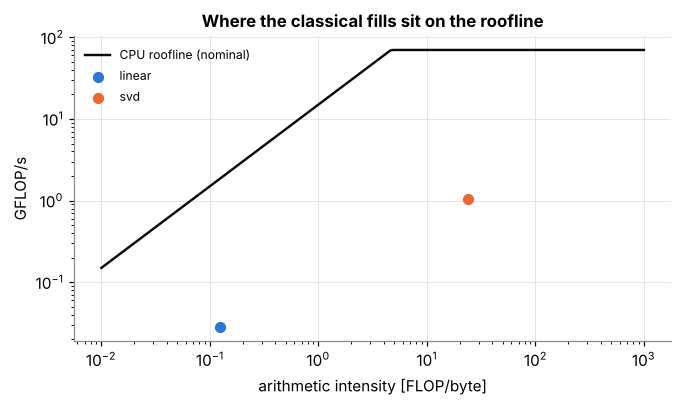

In [10]:
n_missing = 30 * 36
est = profiling.flop_estimates(n_missing, len(y_te), 36, svd_shape=(len(y_te) // 144 + 1, 144))
meas = {"linear": "Linear", "svd": "SVD low-rank (k=3)"}
rows = []
for k, v in est.items():
    t = c.loc[meas[k], "time per series [ms]"] / 1e3 if k in meas else np.nan
    rows.append({"method": k, "FLOPs": v["flops"], "bytes": v["bytes"], "intensity [FLOP/B]": v["intensity"],
                 "achieved GFLOP/s": v["flops"] / t / 1e9 if t == t else np.nan})
fl = pd.DataFrame(rows).set_index("method"); print(fl.to_string(float_format=lambda x: f"{x:.3g}"))
I = np.logspace(-2, 3, 200)
spec = profiling.DEVICES["Colab CPU (2 vCPU, AVX2 FP64, approx.)"]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.loglog(I, profiling.roofline(I, spec["peak_gflops"], spec["bandwidth_gbs"]), color=plotting.INK, label="CPU roofline (nominal)")
for i, (k, row) in enumerate(fl.dropna().iterrows()):
    ax.scatter(row["intensity [FLOP/B]"], row["achieved GFLOP/s"], s=40, color=plotting.PALETTE[i], zorder=3, label=k)
ax.set_xlabel("arithmetic intensity [FLOP/byte]"); ax.set_ylabel("GFLOP/s"); ax.legend(fontsize=8); ax.set_title("Where the classical fills sit on the roofline")
_ = plotting.save(fig, "06_roofline_classical")

**Reading the roofline.** Linear interpolation does about 3 FLOPs per missing point and reads about 24 bytes, so its intensity is far below 1 FLOP/byte and it is *memory/overhead-bound*. Its achieved rate is far under the roof because the time is dominated by Python and NumPy call overhead, not arithmetic. SVD completion has a much higher intensity (dense matrix products) and a higher achieved rate (still only a few % of the nominal peak, because of the Python loop around the SVDs), but it performs about 3 × 10⁴ times more FLOPs than linear for a *worse* answer on CO₂. Linear interpolation costs about 0.1 ms per series, so one core could fill thousands of sensor-series per second. The ridge and forest corrections cost about 0.15–0.25 s per series (mostly feature building in Python), and the BiGRU needs a GPU to train. For this problem cost is not the deciding factor; accuracy per gap length, and its robustness to changes in the building's schedule, are.

## 5. Second target: temperature

In [11]:
st = study.load_study(PROCESSED, "temp")
(ty_tr, tts_tr, to_tr), (_, _, _), (ty_te, tts_te, to_te) = st.part("train"), st.part("val"), st.part("test")
Xt, rt, gt = ft.make_training_set(ty_tr, builder(st, tts_tr, to_tr), gap_lengths=study.GAP_LENGTHS, rng=0)
ridge_t = ml.MLImputer(ml.make_model("ridge", **best_params["ridge"]), builder(st, tts_te, to_te)).fit(Xt, rt)
t_methods = {"Linear": lambda y, c: itp.fill_linear(y),
             "Daily profile + offset": lambda y, c: itp.fill_profile(y, c.ts, profile=st.train_profile),
             "2-D griddata (day x tod)": lambda y, c: itp.fill_grid2d(y, 144, c.midnight_offset, "linear"),
             "Laplace 2-D (w=0.1)": lambda y, c: pde.laplace_fill(y, steps_per_day=144, w_day=0.1, method="direct"),
             "Ridge correction (+occ)": lambda y, c: ridge_t.impute(y)}
t_res = bm.run_benchmark(ty_te, bm.Context(ts=tts_te, occ=to_te, profile=st.train_profile), t_methods, **study.FINAL_PROTOCOL)
bm.summarise(t_res).round(3)

gap_len,1,3,6,18,36,72,144
method,,,,,,,
Laplace 2-D (w=0.1),0.083,0.168,0.296,0.416,0.453,0.551,0.608
2-D griddata (day x tod),0.081,0.132,0.226,0.406,0.486,0.630,0.749
Daily profile + offset,0.120,0.125,0.187,0.331,0.463,0.782,0.787
Ridge correction (+occ),0.180,0.221,0.321,0.344,0.507,0.890,0.903
Linear,0.081,0.115,0.219,0.413,0.698,1.199,1.391


For **temperature**, coupling to neighbouring days still wins on test: the day-coupled Laplace fill cuts the 24-h error of linear interpolation from about 1.4 to 0.6 °C, and 2-D griddata and the profile also beat linear for gaps of 6 h or more. For gaps of 10–30 min, linear or griddata is best. Temperature follows the HVAC schedule, which did not change between periods, so the daily-pattern methods transfer.

## 6. Generalisation: a different sensor, room and year
Sensor `…326` (Sep 2025 – Apr 2026) was never used for any choice. Its CO₂ does not correlate with any occupancy space (notebook 00), so models are applied **without occupancy**. The ridge correction is trained on sensor `…869` and transferred unchanged: its features are relative to each gap's anchors, so they do not depend on the room's absolute level. The typical-day profile is recomputed from the first 8 weeks of `…326`, and only the remaining period is scored.

In [12]:
s2 = study.load_study(PROCESSED, "co2", sensor=study.SECONDARY_SENSOR)
cut = 8 * 7 * 144
prof2 = itp.daily_profile(s2.y[:cut], s2.ts[:cut])
y2, ts2 = s2.y[cut:], s2.ts[cut:]
def prof_vals(ts):
    ts = pd.DatetimeIndex(ts); return prof2.reindex(pd.MultiIndex.from_arrays([ts.dayofweek >= 5, ts.hour * 60 + ts.minute])).to_numpy()
X0, r0, g0 = ft.make_training_set(y_tr, builder(s, ts_tr, o_tr, use_occ=False), gap_lengths=study.GAP_LENGTHS, rng=0)
ridge_transfer = ml.MLImputer(ml.make_model("ridge", **best_params["ridge"]),
                              ft.GapFeatureBuilder(ts2, None, prof_vals(ts2), level_ref=float(np.nanmedian(s2.y[:cut])))).fit(X0, r0)
m2 = {"Linear": lambda y, c: itp.fill_linear(y),
      "Daily profile + offset": lambda y, c: itp.fill_profile(y, c.ts, profile=prof2),
      "Ridge correction (transferred, no occ)": lambda y, c: ridge_transfer.impute(y)}
r2 = bm.run_benchmark(y2, bm.Context(ts=ts2), m2, **study.FINAL_PROTOCOL)
bm.summarise(r2).round(1)

gap_len,1,3,6,18,36,72,144
method,,,,,,,
"Ridge correction (transferred, no occ)",10.8,11.5,16.0,20.4,25.5,26.8,26.6
Daily profile + offset,9.1,11.3,13.9,21.2,26.0,27.7,27.8
Linear,8.8,10.9,13.4,20.9,26.4,28.7,30.2


On the second sensor, the transferred ridge correction is worse than linear for gaps up to an hour, roughly ties at 3–6 h, and is better for gaps of 12–24 h (about 27 vs 29–30 ppm). There, the profile was recomputed on the sensor's own first 8 weeks, which supports the explanation above: the correction helps when its daily-shape information is recent.

## 7. Failure modes, unsupported inputs and limitations

| Situation | What the code does | Consequence / recommendation |
|---|---|---|
| Gap at the start or end of the series (no right/left anchor) | holds the nearest value; ML/deep fall back to the baseline | this is extrapolation; such values are flagged and never scored |
| Gap longer than 24 h | methods still return values; the deep model falls back to linear beyond its window | **unsupported**: errors approach the signal's own variability; report as missing |
| Occupancy missing | treated as 0 after the last event; a silence over 72 h becomes NaN | occupancy features lose value during outages |
| Occupancy not co-located with the CO₂ sensor (true here) | used as a building-activity proxy | physical parameters are *effective*; a room-level occupancy sensor would be needed for a true mass balance |
| Implausible readings (CO₂ < 350 ppm or > 5000 ppm, etc.) | set to NaN before reconstruction | treated as gaps; the audit counts them |
| Distribution shift (end of semester in the test period) | features are relative to the gap anchors | levels transfer, but the *daily shape* learned in semester does not: profile and ridge corrections over-predict on the calmer test period (section 2) |
| Noise floor | — | for gaps of 1–3 samples, no method can beat ≈ 8 ppm RMSE against raw readings |
| Single building, two sensors | — | conclusions about *which method wins at which gap length* are well supported; absolute errors are room-specific |

**What the validation cannot establish.** Artificial gaps are placed at random times, while real outages may cluster at particular times (e.g. at night, or when a gateway reboots). Hidden values are compared with *noisy* readings, so RMSE includes sensor noise. Only one room had a long, clean record suitable as ground truth.

## 8. Final recommendation

In [13]:
best = bm.summarise(test)
winner = best.idxmin()
print("lowest mean test RMSE per gap length:"); print(winner.to_string())
print("\nHybrid policy vs linear interpolation, test RMSE reduction [%]:")
print((100 * (1 - best.loc["Hybrid (validated policy)"] / best.loc["Linear"])).round(1).to_string())

lowest mean test RMSE per gap length:
gap_len
1      Random forest correction (+occ)
3      Random forest correction (+occ)
6      Random forest correction (+occ)
18     Random forest correction (+occ)
36                              Linear
72                  PI-BiGRU (w=0.003)
144                 PI-BiGRU (w=0.003)

Hybrid policy vs linear interpolation, test RMSE reduction [%]:
gap_len
1       0.0
3       0.0
6       0.0
18      0.0
36    -11.0
72     -2.7
144    -6.8


**Recommended policy for this BMS (based on the test evidence, not only validation).**
* **Gaps up to 6 h: linear interpolation.** On the test period no method is significantly better, and it is the cheapest, most transparent and least sensitive to schedule changes.
* **Gaps of 12–24 h: the BiGRU, if a trained model is available, otherwise linear interpolation.** The BiGRU is the only method that beat linear on both validation and test for 24-h gaps, but the test gain is modest (about 12 %) and it needs a GPU to train. Between 6 and 12 h the two are equivalent. The ridge correction and the daily profile are **not** recommended for CO₂: their advantage on validation reversed on test because they rely on the training period's daily schedule.
* **For temperature**, use the day-coupled Laplace fill (w = 0.1) for gaps of 6 h or more.
* **Gaps longer than 24 h, and gaps at the series ends:** report as missing.

The validated hybrid is kept in the results as an honest record: the choice was made correctly on validation data, and it failed on test for a reason that can be identified. Proposed improvements: recompute the daily profile and the ML training set from a rolling window of recent weeks; validate on several periods (rolling origin); and use a room-level occupancy sensor. The full GPU training (3 seeds) confirmed the BiGRU's advantage at 24 h, but also showed that more training does not improve it: more data (more weeks, more rooms) is the way to improve it.